# Arquitectura multiagente con RAG
**Un Supervisor coordina tres agentes; uno de ellos consulta documentos (RAG) · LangGraph + LangChain + Groq + Gradio · Notebook resuelto (local o Colab)**

Seguimos con la **sucursal bancaria ficticia**. Hasta ahora los agentes solo usaban **datos y cálculos** (saldo, cuota). Pero muchas preguntas se responden con **documentos**: *¿cuál es el aporte mínimo?, ¿qué seguro es obligatorio?, ¿en cuánto tiempo responden un reclamo?*

Para eso agregamos un **Agente de Políticas** que busca en el **manual de la sucursal** antes de responder: eso es **RAG**.

> 🧪 **Versión del reto:** el manual son **6 PDFs** (manuales, reglamento y una circular) indexados en **FAISS**, un índice que se guarda en disco para no recalcular los embeddings en cada ejecución. El agente cita **archivo y página**. El código de la versión original (4 archivos `.md` e `InMemoryVectorStore`) sigue en las celdas, comentado.

> ⚠️ Todo es ficticio: políticas, tasas y clientes son inventados para la clase.
> 🔑 Necesitas tu `GROQ_API_KEY`: en Colab, guardada en **Secrets** (icono 🔑 a la izquierda); en local, en el archivo `.env` de la raíz del repositorio. Nunca la pegues en el código.

## 🗺️ La arquitectura
```
                         ┌───────────────────────┐
   Cliente ────────────► │      SUPERVISOR        │ ◄──── cada agente DEVUELVE
                         │ decide a quién delegar │       su resultado
                         └───┬────────┬────────┬──┘
                             │        │        │
               ┌─────────────┘        │        └──────────────┐
               ▼                      ▼                       ▼
   ┌───────────────────────┐ ┌──────────────────┐ ┌──────────────────────┐
   │ 📚 Agente de Políticas │ │ 💰 Agente Cuentas │ │ 🧮 Agente de Créditos │
   │  herramienta: RAG      │ │ saldo, movimient.│ │ simular_cuota         │
   │  busca en el MANUAL    │ │ (Python)         │ │ (Python)              │
   └──────────┬────────────┘ └──────────────────┘ └──────────────────────┘
              ▼
   ┌───────────────────────┐
   │ 🗂️ Índice FAISS        │  ← fragmentos de los 6 PDFs convertidos en vectores (en disco)
   └───────────────────────┘
                     Supervisor: finalizar ──► Respuesta (con fuentes) ──► Cliente
```

### 🧠 ¿Qué es RAG? (*Retrieval-Augmented Generation*)
El LLM **no sabe** las políticas de nuestro banco. En vez de reentrenarlo, le **pasamos los fragmentos relevantes** del manual justo antes de responder.

```
PREPARAR (una vez)                            RESPONDER (cada pregunta)
documentos → dividir en fragmentos            pregunta → embedding → buscar los fragmentos
          → embedding (vector)                          más parecidos → LLM responde
          → guardar en un índice                        SOLO con esos fragmentos + cita la fuente
```

| Concepto | En palabras simples |
|---|---|
| **Fragmento** (*chunk*) | Un pedazo corto del documento (unos párrafos) |
| **Embedding** | Una lista de números que representa el **significado** del texto. Textos parecidos → vectores cercanos |
| **Índice vectorial** | Donde guardamos los vectores para buscar rápido |
| **Recuperar** | Encontrar los *k* fragmentos más parecidos a la pregunta |
| **RAG agéntico** | El **agente decide** cuándo buscar y qué buscar (la búsqueda es una herramienta) |

### 🧭 Recorrido
| Paso | Qué haces |
|---|---|
| 0–2 | Instalar, conectar con Groq, bitácora |
| **Parte A · RAG** | |
| 3 | Leer el **manual**: 6 PDFs ficticios |
| 4 | **Cargar** página por página, limpiar y **dividir** en fragmentos |
| 5 | **Embeddings** e índice **FAISS** guardado en disco |
| 6 | **Recuperar**: probar la búsqueda sola |
| **Parte B · Agentes** | |
| 7 | Herramientas: búsqueda RAG + herramientas de Python |
| 8 | Tres **agentes especialistas** |
| 9 | El **Supervisor** y el grafo de LangGraph |
| 10 | Probar sin interfaz |
| 11 | Ver el grafo |
| 12 | **Gradio**: diagrama de secuencia + fragmentos recuperados |

## Paso 0 · ▶️ Instalar
| Paquete | Para qué |
|---|---|
| `langchain`, `langgraph`, `langchain-groq` | Agentes, grafo y LLM |
| `langchain-huggingface` | Modelo de **embeddings** gratuito (corre en tu equipo o en Colab, sin API key) |
| `langchain-text-splitters` | Dividir documentos en fragmentos |
| `pypdf`, `langchain-community` | Leer los PDFs página por página (`PyPDFLoader`) |
| `faiss-cpu` | Índice vectorial **FAISS**, que se puede guardar en disco |
| `python-dotenv` | Lee la clave de `.env` cuando se ejecuta en tu PC |

Colab **ya trae** `sentence-transformers`, `gradio` y `pandas`. Fuera de Colab, la celda los instala **solo si faltan**, así no cambiamos las versiones de Colab. En local lo recomendable es instalar antes `laboratorio-6/requirements.txt` (ver el README).
> Si aparecen avisos rojos de dependencias de paquetes que no usamos, puedes ignorarlos.

In [1]:
# Instalamos SOLO lo que falta. sentence-transformers, gradio y pandas ya vienen en Colab:
# solo se instalan si faltan (por ejemplo en tu PC), así no cambiamos las versiones de Colab
import importlib.util
MODULOS = {'sentence-transformers': 'sentence_transformers', 'gradio': 'gradio', 'pandas': 'pandas'}
faltantes = ' '.join(p for p, m in MODULOS.items() if importlib.util.find_spec(m) is None)
# %pip install -q langchain langgraph langchain-groq langchain-huggingface langchain-text-splitters python-dotenv {faltantes}
# NUEVO (reto): pypdf y langchain-community leen los PDFs; faiss-cpu es el índice que se guarda en disco
%pip install -q langchain langgraph langchain-groq langchain-huggingface langchain-text-splitters python-dotenv pypdf langchain-community faiss-cpu {faltantes}

Note: you may need to restart the kernel to use updated packages.


## Paso 1 · ▶️ Conectar con Groq
Lee la clave desde `.env` (en local) o desde **Secrets** de Colab y prueba el modelo.

**📤 Salida esperada:** `conectado`

In [2]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq

# Buscamos la clave de Groq SIN escribirla en el código
load_dotenv()                                    # en tu PC: carga el archivo .env si existe
GROQ_API_KEY = os.getenv('GROQ_API_KEY')
if not GROQ_API_KEY:
    try:
        # En Colab: la leemos de Secrets (icono 🔑 a la izquierda)
        from google.colab import userdata
        GROQ_API_KEY = userdata.get('GROQ_API_KEY')
    except ImportError:
        pass                                     # fuera de Colab este módulo no existe
if not GROQ_API_KEY:
    raise ValueError('Configura GROQ_API_KEY en .env (en tu PC) o en Secrets de Colab.')

MODELO = 'openai/gpt-oss-120b'

def nuevo_llm():
    # temperature=0: respuestas lo más estables posible
    return ChatGroq(model=MODELO, api_key=GROQ_API_KEY, temperature=0, reasoning_effort='low')

print(nuevo_llm().invoke('Responde solo: conectado').content)

conectado


## Paso 2 · ▶️ Bitácora compartida
Cada vez que alguien le envía algo a otro, lo **anotamos**. Gradio leerá esta lista para dibujar el diagrama.

In [3]:
import time, json

BITACORA = []            # mensajes entre participantes
FRAGMENTOS_USADOS = []   # fragmentos que recuperó el RAG (para mostrarlos en Gradio)

def registrar(de, para, tipo, accion, detalle=''):
    BITACORA.append({
        'de': de, 'para': para,
        'tipo': tipo,                 # 'Pregunta', 'Delegación', 'Resultado', 'RAG', 'Herramienta', 'Respuesta'
        'accion': accion,
        'detalle': detalle if isinstance(detalle, str) else json.dumps(detalle, ensure_ascii=False),
    })

print('Bitácora lista.')

Bitácora lista.


# Parte A · RAG: preparar el conocimiento

## Paso 3 · ▶️ El manual de la sucursal (6 PDFs)
En la versión original creábamos 4 archivos `.md` cortos (el código sigue en la celda, comentado). En un banco real el manual **llega en PDF**, así que ahora leemos los **6 PDFs** de la carpeta `manual_pdf/`.

| Archivo | Código | Páginas | Tema |
|---|---|---|---|
| `01_Manual_Credito_Vehicular.pdf` | MCV-003 | 3 | Vehículos financiables, aporte, plazos, tasa, cuota, capacidad de pago, desembolso, mora |
| `02_Requisitos_y_Documentacion.pdf` | RDS-002 | 2 | Requisitos, antigüedad laboral, documentos por perfil, codeudor |
| `03_Seguros_Tarifas_y_Cargos.pdf` | SEG-002 | 2 | Seguros obligatorios y opcionales, tarifas, mora |
| `04_Atencion_Reclamos_y_Datos.pdf` | ATR-001 | 2 | Horarios, canales y tiempos de reclamos, datos personales |
| `05_Reglamento_Cuentas_de_Ahorro.pdf` | RCA-001 | 2 | Tipos de cuenta, retiros, inactividad |
| `06_Circular_2026-07_Actualizacion.pdf` | CIR-2026-07 | 1 | **Modifica** MCV-003 y ATR-001 desde el 1-09-2026 |

> ⚠️ La circular **contradice** al manual: el aporte mínimo para motos nuevas pasa del 10 % al **15 %**. Un buen RAG debe encontrar las dos fuentes y aplicar la vigente.
> ☁️ En Colab, sube la carpeta `manual_pdf/` con los 6 PDFs junto al notebook antes de ejecutar este paso.

In [4]:
# ═══════════════ CÓDIGO ORIGINAL (comentado, no se ejecuta) ═══════════════
# Creaba 4 archivos .md cortos en manual/ a partir de un diccionario de textos.
# from pathlib import Path
#
# MANUAL = {
# 'credito_vehicular.md': '''# Crédito vehicular (política ficticia)
# El crédito vehicular financia motos y carros nuevos o usados de hasta 5 años de antigüedad.
# El aporte mínimo del cliente es el 20 % del precio del vehículo. Para motos el aporte mínimo es el 10 %.
# El plazo mínimo es de 12 meses y el plazo máximo es de 72 meses para carros y de 48 meses para motos.
# La tasa de referencia es del 1 % mensual fija durante todo el crédito.
# La cuota mensual no debe superar el 35 % del ingreso mensual menos las obligaciones actuales del cliente.
# El banco puede financiar hasta el 100 % del valor restante después del aporte.''',
#
# 'requisitos.md': '''# Requisitos del solicitante (política ficticia)
# El solicitante debe ser mayor de 18 años y tener una cuenta activa en la sucursal.
# Documentos obligatorios: documento de identidad, certificado de ingresos de los últimos 3 meses y
# extractos bancarios de los últimos 3 meses.
# Los trabajadores independientes deben presentar además la declaración de renta del último año.
# La antigüedad laboral mínima es de 6 meses para empleados y de 12 meses para independientes.
# No se aceptan solicitudes con reportes negativos vigentes en centrales de riesgo.''',
#
# 'seguros_y_cargos.md': '''# Seguros y cargos (política ficticia)
# Todo crédito incluye un seguro de vida deudor obligatorio con costo del 0,1 % mensual sobre el saldo.
# Para crédito vehicular también es obligatorio un seguro todo riesgo del vehículo, que el cliente
# puede contratar con la aseguradora que prefiera.
# El estudio de crédito no tiene costo. El pago anticipado total o parcial no tiene penalidad.
# Los pagos con más de 5 días de atraso generan intereses de mora.''',
#
# 'atencion_y_reclamos.md': '''# Atención y reclamos (política ficticia)
# La sucursal atiende de lunes a viernes de 8:00 a 16:00 y los sábados de 9:00 a 12:00.
# Los reclamos se pueden presentar en la sucursal, en la línea de atención o en la página web.
# El banco responde los reclamos en un máximo de 15 días hábiles.
# Si el cliente no está satisfecho con la respuesta, puede acudir al defensor del consumidor financiero.''',
# }
#
# carpeta = Path('manual')
# carpeta.mkdir(exist_ok=True)
# for nombre, texto in MANUAL.items():
#     (carpeta / nombre).write_text(texto, encoding='utf-8')
#
# print('Documentos creados:', sorted(p.name for p in carpeta.glob('*.md')))

# ═══════════════ NUEVO · reto: manual en PDF + índice FAISS en disco ═══════════════
# ¿Por qué? En un banco real el manual llega en PDF (manuales, reglamentos, circulares), no en .md
# escritos a mano. Ya no creamos documentos: leemos los PDFs que están en manual_pdf/.
from pathlib import Path

carpeta_pdf = Path('manual_pdf')
pdfs = sorted(carpeta_pdf.glob('*.pdf'))       # sorted: el orden de indexación es siempre el mismo

# Comprobación temprana: sin PDFs, el resto de la Parte A no tendría nada que indexar.
if not pdfs:
    raise FileNotFoundError(f'No hay PDFs en {carpeta_pdf.resolve()}. Copia ahí los 6 PDFs del manual.')

print(f'{len(pdfs)} PDFs en {carpeta_pdf}/:')
for p in pdfs:
    print(f'  · {p.name}  ({p.stat().st_size / 1024:.1f} KB)')

6 PDFs en manual_pdf/:
  · 01_Manual_Credito_Vehicular.pdf  (7.5 KB)
  · 02_Requisitos_y_Documentacion.pdf  (5.0 KB)
  · 03_Seguros_Tarifas_y_Cargos.pdf  (5.1 KB)
  · 04_Atencion_Reclamos_y_Datos.pdf  (4.6 KB)
  · 05_Reglamento_Cuentas_de_Ahorro.pdf  (4.4 KB)
  · 06_Circular_2026-07_Actualizacion.pdf  (2.8 KB)


## Paso 4 · ▶️ Cargar página por página y dividir en fragmentos
`PyPDFLoader` convierte cada **página** en un `Document`: así cada fragmento sabe de qué página salió y el agente puede citar **archivo y página**.

| Cambio respecto a la versión original | Por qué |
|---|---|
| Un `Document` **por página** con `metadata['pagina']` | Para citar `[archivo.pdf, p. N]` |
| Se quita el **encabezado** que se repite en cada página | Repetido en todos los fragmentos, los haría parecerse entre sí y empeoraría la búsqueda |
| Se copian `codigo` y `vigente_desde` a cada fragmento | Para decidir qué norma prevalece cuando la circular modifica un manual |
| Se lee qué documentos **modifica** cada circular (`MODIFICADO_POR`) | Para adjuntar la circular cuando se recupera un documento que ella cambió (paso 6) |
| `chunk_size=800`, `chunk_overlap=120` (antes 300 y 50) | Las tablas del PDF salen con una celda por línea: con 300 caracteres una fila quedaría partida |

In [5]:
# ═══════════════ CÓDIGO ORIGINAL (comentado, no se ejecuta) ═══════════════
# Cargaba los .md completos (un Document por archivo) y los dividía en fragmentos de 300 caracteres.
# from langchain_core.documents import Document
# from langchain_text_splitters import RecursiveCharacterTextSplitter
#
# # 1) CARGAR: cada archivo se convierte en un Document (texto + metadatos)
# documentos = [Document(page_content=p.read_text(encoding='utf-8'), metadata={'fuente': p.name})
#               for p in sorted(carpeta.glob('*.md'))]
#
# # 2) DIVIDIR: cortamos respetando párrafos y líneas cuando se puede
# divisor = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=50)
# fragmentos = divisor.split_documents(documentos)     # cada fragmento conserva su 'fuente'
#
# print(f'{len(documentos)} documentos → {len(fragmentos)} fragmentos\n')
# ejemplo = fragmentos[0]
# print('Ejemplo de fragmento:')
# print('  fuente:', ejemplo.metadata['fuente'])
# print('  texto :', ejemplo.page_content)

# ═══════════════ NUEVO · reto: manual en PDF + índice FAISS en disco ═══════════════
import re
from langchain_core.documents import Document
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

# Cada página repite tres líneas: el aviso de documento simulado, "Página N" y el nombre del banco.
# Las quitamos: no aportan información y, repetidas en todos los fragmentos, los harían parecerse.
ENCABEZADO = re.compile(r'^(DOCUMENTO SIMULADO.*|Página \d+|Banco Ficticio S\.A\. · .*)\n?', re.MULTILINE)
# El código y la fecha de vigencia aparecen una sola vez, en la primera página de cada PDF.
CABECERA = re.compile(r'Código:\s*(\S+).*?Vigente desde:\s*(.+?)\s*·', re.DOTALL)

# 1) CARGAR: PyPDFLoader devuelve UN Document POR PÁGINA (metadata['page'] empieza en 0)
documentos = []
for pdf in pdfs:
    paginas = PyPDFLoader(str(pdf)).load()
    cabecera = CABECERA.search(paginas[0].page_content)
    codigo = cabecera.group(1) if cabecera else ''
    vigente = ' '.join(cabecera.group(2).split()) if cabecera else ''   # une la fecha si quedó en dos líneas
    for pagina in paginas:
        documentos.append(Document(
            page_content=ENCABEZADO.sub('', pagina.page_content).strip(),
            metadata={'fuente': pdf.name,
                      'pagina': pagina.metadata['page'] + 1,   # +1: página 1, 2, 3… como la ve una persona
                      'codigo': codigo,                       # copiados a TODAS las páginas: la circular
                      'vigente_desde': vigente}))             # modifica manuales y hay que saber cuál rige

# ¿Qué documentos modifica cada circular? Lo dice su propio texto ("modifica los documentos MCV-003
# y ATR-001"). Lo guardamos como {documento modificado: [circulares]} para usarlo al buscar (paso 6).
MODIFICADO_POR = {}
for d in documentos:
    declaracion = re.search(r'modifica los documentos (.+?)\.', ' '.join(d.page_content.split()))
    if declaracion:
        for modificado in re.findall(r'[A-Z]{3}-\d{3}', declaracion.group(1)):
            MODIFICADO_POR.setdefault(modificado, []).append(d.metadata['codigo'])

# 2) DIVIDIR: fragmentos más grandes que con los .md porque las tablas del PDF se extraen con una
#    celda por línea; con 300 caracteres una fila ("Moto nueva · 10 % · 48 meses") quedaría partida
TAMANO_FRAGMENTO, SOLAPAMIENTO = 800, 120
divisor = RecursiveCharacterTextSplitter(chunk_size=TAMANO_FRAGMENTO, chunk_overlap=SOLAPAMIENTO)
fragmentos = divisor.split_documents(documentos)   # cada fragmento hereda fuente, página, código y vigencia

print(f'{len(pdfs)} PDFs → {len(documentos)} páginas → {len(fragmentos)} fragmentos\n')
for pdf in pdfs:
    n = sum(f.metadata['fuente'] == pdf.name for f in fragmentos)
    print(f'  {pdf.name:<40} {n} fragmentos')
print('\nDocumentos modificados por circulares:', MODIFICADO_POR)
ejemplo = next(f for f in fragmentos if f.metadata['codigo'] == 'CIR-2026-07')
print('\nEjemplo de fragmento:')
print('  metadatos:', ejemplo.metadata)
print('  texto    :', ejemplo.page_content[:300], '…')

C:\Users\A47x\AppData\Local\Temp\ipykernel_14128\1267063701.py:23: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


6 PDFs → 12 páginas → 24 fragmentos

  01_Manual_Credito_Vehicular.pdf          7 fragmentos
  02_Requisitos_y_Documentacion.pdf        4 fragmentos
  03_Seguros_Tarifas_y_Cargos.pdf          4 fragmentos
  04_Atencion_Reclamos_y_Datos.pdf         4 fragmentos
  05_Reglamento_Cuentas_de_Ahorro.pdf      3 fragmentos
  06_Circular_2026-07_Actualizacion.pdf    2 fragmentos

Documentos modificados por circulares: {'MCV-003': ['CIR-2026-07'], 'ATR-001': ['CIR-2026-07']}

Ejemplo de fragmento:
  metadatos: {'fuente': '06_Circular_2026-07_Actualizacion.pdf', 'pagina': 1, 'codigo': 'CIR-2026-07', 'vigente_desde': '1 de septiembre de 2026'}
  texto    : Circular 2026-07: Actualización de Políticas
Código: CIR-2026-07 · Versión: 1.0 · Vigente desde: 1 de septiembre de 2026 · Área responsable: Gerencia de la
Sucursal Demo
Asunto
Actualización de condiciones de crédito para motos, horario de atención de los sábados y canales de
reclamo. Esta circular  …


## Paso 5 · ▶️ Embeddings e índice FAISS en disco
El modelo de embeddings es el mismo (multilingüe, gratuito, corre en tu equipo; ~470 MB la primera vez). Lo que cambia es **dónde viven los vectores**:

| | `InMemoryVectorStore` (original) | `FAISS` (reto) |
|---|---|---|
| Dónde guarda | En la memoria del kernel | En disco: `indice_faiss/index.faiss` (vectores) e `index.pkl` (textos y metadatos) |
| Al reiniciar el kernel | Recalcula **todos** los embeddings | **Carga** el índice sin recalcular |
| Escala | Decenas o cientos de fragmentos | Millones de vectores |

Para saber si el índice del disco sigue sirviendo guardamos una **huella** (*hash*) de los PDFs, de los parámetros de división y del modelo. Si algo cambia, el índice se reconstruye solo.

**📤 Salida esperada:** la primera vez, `🧱 Índice creado…`; en las siguientes, `♻️ Índice cargado…`.

In [6]:
# ═══════════════ CÓDIGO ORIGINAL (comentado, no se ejecuta) ═══════════════
# Calculaba los embeddings de todos los fragmentos y los guardaba en memoria (InMemoryVectorStore).
# from langchain_huggingface import HuggingFaceEmbeddings
# from langchain_core.vectorstores import InMemoryVectorStore
#
# # 1) Modelo de embeddings (corre en tu equipo o en Colab, sin API key)
# embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
#
# # Veamos qué es un embedding: un texto → una lista de números
# vector = embeddings.embed_query('aporte mínimo para comprar una moto')
# print(f'Un texto se convierte en {len(vector)} números. Los primeros 5: {[round(x, 3) for x in vector[:5]]}')
#
# # 2) Índice: calcula el embedding de CADA fragmento y lo guarda
# indice = InMemoryVectorStore.from_documents(fragmentos, embeddings)
# print(f'Índice listo con {len(fragmentos)} fragmentos.')

# ═══════════════ NUEVO · reto: manual en PDF + índice FAISS en disco ═══════════════
import hashlib
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_community.vectorstores.utils import DistanceStrategy

MODELO_EMBEDDINGS = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'

# 1) Modelo de embeddings. Hace falta aunque el índice ya exista: cada PREGUNTA se convierte en vector.
#    normalize_embeddings=True deja los vectores con longitud 1; así el producto interno ES la
#    similitud coseno, la misma medida que usaba InMemoryVectorStore.
embeddings = HuggingFaceEmbeddings(model_name=MODELO_EMBEDDINGS, encode_kwargs={'normalize_embeddings': True})

vector = embeddings.embed_query('aporte mínimo para comprar una moto')
print(f'Un texto se convierte en {len(vector)} números. Los primeros 5: {[round(x, 3) for x in vector[:5]]}')

# 2) FAISS mide por defecto distancia L2 (más BAJO = más parecido). Pedimos producto interno para que
#    el score conserve el sentido del paso 6 (más ALTO = más parecido). save_local no guarda esta
#    opción, por eso se pasa igual al crear y al cargar.
OPCIONES_FAISS = {'distance_strategy': DistanceStrategy.MAX_INNER_PRODUCT}
CARPETA_INDICE = Path('indice_faiss')

# 3) Huella: resume todo lo que cambia el índice (bytes de cada PDF, división y modelo).
#    Si algo cambia, la huella cambia y se reconstruye; así nunca se usa un índice desactualizado.
h = hashlib.sha256()
for pdf in pdfs:
    h.update(pdf.name.encode() + pdf.read_bytes())
h.update(f'{TAMANO_FRAGMENTO}|{SOLAPAMIENTO}|{MODELO_EMBEDDINGS}'.encode())
huella = h.hexdigest()
archivo_huella = CARPETA_INDICE / 'huella.txt'

inicio = time.time()
if archivo_huella.exists() and archivo_huella.read_text() == huella:
    # allow_dangerous_deserialization: index.pkl se lee con pickle, que puede ejecutar código al cargar.
    # Es seguro SOLO porque este índice lo creamos nosotros; nunca cargues uno que hayas descargado.
    indice = FAISS.load_local(str(CARPETA_INDICE), embeddings, allow_dangerous_deserialization=True, **OPCIONES_FAISS)
    print(f'♻️ Índice cargado de {CARPETA_INDICE}/ con {indice.index.ntotal} vectores '
          f'en {time.time() - inicio:.2f} s, sin recalcular embeddings.')
else:
    indice = FAISS.from_documents(fragmentos, embeddings, **OPCIONES_FAISS)   # calcula un embedding por fragmento
    indice.save_local(str(CARPETA_INDICE))                                    # escribe index.faiss e index.pkl
    archivo_huella.write_text(huella)                                         # la huella se escribe al final
    print(f'🧱 Índice creado con {indice.index.ntotal} vectores en {time.time() - inicio:.2f} s '
          f'y guardado en {CARPETA_INDICE}/.')

C:\Users\A47x\OneDrive\A47x\ARQUITECTURAS-EN-INTELIGENCIA-ARTIFICIAL-MULTIAGENTICA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4734.03it/s]

Un texto se convierte en 384 números. Los primeros 5: [0.001, 0.143, -0.026, -0.044, 0.016]


🧱 Índice creado con 24 vectores en 0.39 s y guardado en indice_faiss/.


## Paso 6 · ▶️ Recuperar: probar la búsqueda sola
Antes de dárselo a un agente, comprobamos que la búsqueda **encuentra lo correcto**. El *score* es la similitud coseno (más alto = más parecido) y cada resultado indica **archivo y página**.

**🤔 Predice:** para «¿cuánto debo dar de cuota inicial por una moto nueva?», ¿qué archivos y páginas deberían salir? ¿Aparece la circular?

La **similitud sola no basta** cuando un documento modifica a otro: la circular habla de «motos» y «aporte», pero el manual tiene más fragmentos sobre el tema y suele ganarle. En una ejecución de prueba, con la consulta que redactó el agente, la circular quedó fuera incluso con k=4 y la respuesta usó el 10 % derogado. Por eso `buscar` hace dos cosas:

| | Qué hace | Cómo |
|---|---|---|
| 1 | Los *k*=3 fragmentos más parecidos (como en la versión original) | `similarity_search_with_score` |
| 2 | Si alguno viene de un documento que una circular modifica, **adjunta** el fragmento de esa circular más parecido a la consulta | Búsqueda con **filtro por metadatos**: `filter={'codigo': 'CIR-2026-07'}` |

In [7]:
# ═══════════════ CÓDIGO ORIGINAL (comentado, no se ejecuta) ═══════════════
# Buscaba los 3 fragmentos más parecidos en el índice en memoria y mostraba solo el archivo.
# def buscar(consulta, k=3):
#     # Devuelve los k fragmentos más parecidos a la consulta, con su puntaje
#     return indice.similarity_search_with_score(consulta, k=k)
#
# for doc, score in buscar('¿Cuánto debo dar de cuota inicial por una moto?'):
#     print(f'[{score:.2f}] {doc.metadata["fuente"]}: {doc.page_content[:110]}…')

# ═══════════════ NUEVO · reto: manual en PDF + índice FAISS en disco ═══════════════
def buscar(consulta, k=3):
    # 1) Igual que antes: los k fragmentos más parecidos, ahora sobre FAISS
    resultados = indice.similarity_search_with_score(consulta, k=k)
    # 2) La similitud no sabe de vigencias: si un resultado viene de un documento que una circular
    #    modifica (MODIFICADO_POR, paso 4), adjuntamos el fragmento de esa circular más parecido a la
    #    consulta. filter= busca SOLO entre los fragmentos cuyos metadatos coinciden.
    circulares = sorted({cir for d, _ in resultados for cir in MODIFICADO_POR.get(d.metadata['codigo'], [])})
    for cir in circulares:
        for d, s in indice.similarity_search_with_score(consulta, k=1, filter={'codigo': cir}):
            if all(d.page_content != r.page_content for r, _ in resultados):   # no repetir si ya estaba
                resultados.append((d, s))
    return resultados

consulta = '¿Cuánto debo dar de cuota inicial por una moto nueva?'
por_similitud = {d.page_content for d, _ in indice.similarity_search_with_score(consulta, k=3)}
for doc, score in buscar(consulta):
    # Mostramos también la página y la vigencia: son los datos que el agente usará para citar
    origen = '' if doc.page_content in por_similitud else '   📎 adjuntada: modifica un documento recuperado'
    print(f'[{score:.2f}] {doc.metadata["fuente"]} p. {doc.metadata["pagina"]} '
          f'(vigente desde {doc.metadata["vigente_desde"]}){origen}\n        {" ".join(doc.page_content.split())[:120]}…')

[0.75] 01_Manual_Credito_Vehicular.pdf p. 2 (vigente desde 15 de enero de 2026)
        cobran por separado según el documento SEG-002. Ejemplo 1. Moto nueva de $20.000.000 con aporte de $5.000.000 a 36 meses…
[0.63] 01_Manual_Credito_Vehicular.pdf p. 1 (vigente desde 15 de enero de 2026)
        vehículos importados sin documentación aduanera completa. 4. Condiciones por tipo de vehículo La siguiente tabla resume …
[0.53] 01_Manual_Credito_Vehicular.pdf p. 1 (vigente desde 15 de enero de 2026)
        cuota inicial. Capital financiado: precio del vehículo menos el aporte. Plazo: número de cuotas mensuales pactadas. Cuot…
[0.38] 06_Circular_2026-07_Actualizacion.pdf p. 1 (vigente desde 1 de septiembre de 2026)   📎 adjuntada: modifica un documento recuperado
        Circular 2026-07: Actualización de Políticas Código: CIR-2026-07 · Versión: 1.0 · Vigente desde: 1 de septiembre de 2026…


**🤔 Observa:** la pregunta dice «cuota inicial» y el manual dice «aporte mínimo». No comparten palabras, pero sí **significado**: eso es lo que captura el embedding.

**🤔 Observa también:** la circular no está entre los 3 más parecidos, pero se **adjunta** (📎) porque modifica al manual de crédito vehicular. El agente recibe las dos versiones (10 % y 15 %) con su fecha de vigencia; decidir cuál rige es trabajo suyo.

# Parte B · La arquitectura multiagente

## Paso 7 · ▶️ Las herramientas
| Herramienta | Agente | Qué hace |
|---|---|---|
| `buscar_en_manual` | Políticas | **RAG**: recupera fragmentos del índice FAISS y los devuelve con **archivo, página y vigencia** |
| `consultar_saldo`, `consultar_movimientos` | Cuentas | Leen la cuenta ficticia (Python) |
| `simular_cuota` | Créditos | Calcula la cuota (Python) |

El **docstring** de cada herramienta es lo que el LLM lee para decidir cuándo usarla.

In [8]:
from langchain.tools import tool

# ── Herramienta RAG ────────────────────────────────────────────────
@tool
def buscar_en_manual(consulta: str) -> str:
    # '''Busca en el manual de políticas de la sucursal (crédito vehicular, requisitos,
    # seguros, cargos, horarios y reclamos). Devuelve fragmentos con su fuente.'''
    # resultados = buscar(consulta, k=3)
    # FRAGMENTOS_USADOS.extend({'consulta': consulta, 'fuente': d.metadata['fuente'],
    #                           'score': round(s, 2), 'texto': d.page_content} for d, s in resultados)
    # registrar('Agente Políticas', 'Agente Políticas', 'RAG', f'busca: «{consulta[:40]}»',
    #           [d.metadata['fuente'] for d, _ in resultados])
    # # Formato que verá el LLM: cada fragmento con su fuente para poder citarla
    # return '\n\n'.join(f'[{d.metadata["fuente"]}] {d.page_content}' for d, _ in resultados)

    # NUEVO (reto): el docstring menciona los temas nuevos (cuentas de ahorro, circulares) porque es
    # lo que el LLM lee para decidir qué buscar
    '''Busca en el manual de políticas de la sucursal (crédito vehicular, requisitos, seguros,
    tarifas, horarios, reclamos, cuentas de ahorro y circulares que actualizan esas políticas).
    Devuelve fragmentos con archivo, página y fecha de vigencia.'''
    resultados = buscar(consulta)                    # k=3 + circulares que modifican lo recuperado (paso 6)
    # Guardamos también la página para mostrarla en la tabla de Gradio; float() convierte el
    # número de numpy que devuelve FAISS en un número normal de Python
    FRAGMENTOS_USADOS.extend({'consulta': consulta, 'fuente': d.metadata['fuente'], 'pagina': d.metadata['pagina'],
                              'score': round(float(s), 2), 'texto': d.page_content} for d, s in resultados)
    registrar('Agente Políticas', 'Agente Políticas', 'RAG', f'busca: «{consulta[:40]}»',
              [f'{d.metadata["fuente"]} p. {d.metadata["pagina"]}' for d, _ in resultados])
    # Formato que verá el LLM: la cita lista para copiar [archivo, p. N] más el código y la vigencia,
    # para que pueda aplicar la norma más reciente cuando la circular modifica un manual
    return '\n\n'.join(f'[{d.metadata["fuente"]}, p. {d.metadata["pagina"]}] '
                        f'({d.metadata["codigo"]}, vigente desde {d.metadata["vigente_desde"]})\n{d.page_content}'
                        for d, _ in resultados)

# ── Herramientas de Python (datos y cálculos) ─────────────────────
CUENTA = {'saldo_cop': 5_000_000,
          'movimientos': [{'concepto': 'Saldo inicial', 'valor_cop': 4_000_000},
                          {'concepto': 'Ingreso ficticio', 'valor_cop': 3_000_000},
                          {'concepto': 'Gastos ficticios', 'valor_cop': -2_000_000}]}

@tool
def consultar_saldo() -> dict:
    '''Devuelve el saldo disponible (COP) del cliente DEMO-001.'''
    registrar('Agente Cuentas', 'Agente Cuentas', 'Herramienta', 'consultar_saldo')
    return {'saldo_cop': CUENTA['saldo_cop']}

@tool
def consultar_movimientos() -> dict:
    '''Devuelve los movimientos y el saldo final del cliente DEMO-001.'''
    registrar('Agente Cuentas', 'Agente Cuentas', 'Herramienta', 'consultar_movimientos')
    return {'movimientos': CUENTA['movimientos'],
            'saldo_final_cop': sum(m['valor_cop'] for m in CUENTA['movimientos'])}

@tool
def simular_cuota(precio_cop: int, aporte_cop: int, meses: int) -> dict:
    '''Simula la cuota mensual fija de un crédito vehicular a la tasa de referencia del 1 % mensual.'''
    registrar('Agente Créditos', 'Agente Créditos', 'Herramienta', 'simular_cuota',
              {'precio': precio_cop, 'aporte': aporte_cop, 'meses': meses})
    capital = precio_cop - aporte_cop
    cuota = capital * 0.01 / (1 - (1 + 0.01) ** (-meses))     # fórmula de anualidad
    return {'capital_cop': capital, 'meses': meses, 'cuota_aproximada_cop': round(cuota)}

print('Herramientas listas.')

Herramientas listas.


## Paso 8 · ▶️ Los tres agentes especialistas
Cada agente es un `create_agent` de LangChain (un pequeño grafo de LangGraph: *LLM ⇄ herramientas*) con **sus propias** herramientas e instrucciones.

La instrucción clave del agente RAG: **responder SOLO con los fragmentos y citar archivo y página**, y si dos fragmentos se contradicen, **aplicar el de vigencia más reciente**. Si no lo encuentra, debe decirlo en vez de inventar.

> 🔁 A veces el modelo `gpt-oss` de Groq genera una llamada a herramienta mal formada y Groq responde `400 output_parse_failed`. `ModelRetryMiddleware` repite esa llamada (hasta 2 veces más) en lugar de detener el flujo. Los nombres de herramienta también importan: con un nombre como `listar_movimientos` el modelo tendía a escribir `lista_movimientos`; por eso se usa `consultar_movimientos`, con el mismo verbo que `consultar_saldo`.

In [9]:
from groq import BadRequestError
from langchain.agents import create_agent
from langchain.agents.middleware import ModelRetryMiddleware

INSTRUCCIONES = {
    # 'politicas': ('Eres el Agente de Políticas de un banco ficticio. SIEMPRE usa buscar_en_manual antes de responder. '
    #               'Responde SOLO con información de los fragmentos y cita la fuente entre corchetes, ej. [requisitos.md]. '
    #               'Si el manual no lo dice, responde: "El manual no tiene esa información". Máximo 4 frases.'),
    # NUEVO (reto): la cita incluye la página, y hay una regla para las contradicciones,
    # porque la circular 2026-07 cambia el aporte de motos nuevas y el horario de los sábados
    'politicas': ('Eres el Agente de Políticas de un banco ficticio. SIEMPRE usa buscar_en_manual antes de responder. '
                  'Responde SOLO con información de los fragmentos y cita archivo y página copiando la etiqueta '
                  'entre corchetes [ ] tal como aparece al inicio de cada fragmento, ej. [02_Requisitos_y_Documentacion.pdf, p. 1]. '
                  'Si dos fragmentos se contradicen, aplica el de fecha de vigencia más reciente (las circulares '
                  'modifican los manuales) y cita ambos. '
                  'Si el manual no lo dice, responde: "El manual no tiene esa información". Máximo 4 frases.'),
    'cuentas':   'Eres el Agente de Cuentas. Usa tus herramientas para saldo y movimientos. No inventes cifras. Máximo 3 frases.',
    'creditos':  ('Eres el Agente de Créditos. Usa simular_cuota para cualquier cálculo. '
                  'Responde con las cifras de la herramienta. Nunca apruebes créditos. Máximo 3 frases.'),
}
HERRAMIENTAS = {
    'politicas': [buscar_en_manual],
    'cuentas':   [consultar_saldo, consultar_movimientos],
    'creditos':  [simular_cuota],
}

def crear_especialista(nombre):
    # Si Groq no logra interpretar la llamada a herramienta (error 400), la repetimos
    reintento = ModelRetryMiddleware(max_retries=2, retry_on=(BadRequestError,), on_failure='error')
    return create_agent(model=nuevo_llm(), tools=HERRAMIENTAS[nombre], system_prompt=INSTRUCCIONES[nombre],
                        middleware=[reintento])

# Prueba rápida del agente RAG por sí solo
r = crear_especialista('politicas').invoke({'messages': [('user', '¿Cuál es el plazo máximo para una moto?')]})
print(r['messages'][-1].content)

El plazo máximo es de 48 meses para motos nuevas y de 36 meses para motos usadas.  
[01_Manual_Credito_Vehicular.pdf, p. 1] – tabla de plazos por tipo de vehículo.  
[06_Circular_2026-07_Actualizacion.pdf, p. 1] – confirma que el plazo máximo para motos nuevas se mantiene en 48 meses.


## Paso 9 · ▶️ El Supervisor y el grafo
El **Supervisor** no responde preguntas: **decide a quién delegar** y con qué tarea concreta. Usa una **salida estructurada** (`Decision`) validada con Pydantic, así solo puede elegir agentes que existen.

```
START → supervisor ─┬─► politicas ─┐
           ▲        ├─► cuentas  ──┤  (todos VUELVEN al supervisor)
           │        ├─► creditos ──┘
           └────────┘
                    └─ finalizar → respuesta → END
```

| Nodo | Qué hace |
|---|---|
| `supervisor` | Lee la pregunta y lo que ya respondieron los agentes; elige el siguiente o `finalizar` |
| `politicas` / `cuentas` / `creditos` | Ejecutan su agente con la **tarea** que les dio el supervisor y guardan su **aporte** |
| `respuesta` | Un LLM une los aportes en una respuesta final, **conservando las citas** |

In [10]:
from typing import TypedDict, Literal
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END

AGENTES = {'politicas': 'Agente Políticas', 'cuentas': 'Agente Cuentas', 'creditos': 'Agente Créditos'}
LIMITE_DECISIONES = 5    # freno anti-ciclos

# ── 1) Estado del grafo ────────────────────────────────────────────
class Estado(TypedDict):
    pregunta: str          # lo que preguntó el cliente
    aportes: dict          # {'politicas': 'texto...', 'cuentas': '...'}
    siguiente: str         # decisión del supervisor
    tarea: str             # instrucción concreta para el agente elegido
    decisiones: int        # contador
    respuesta: str         # texto final

# ── 2) Contrato de la decisión del supervisor ──────────────────────
class Decision(BaseModel):
    siguiente: Literal['politicas', 'cuentas', 'creditos', 'finalizar']
    tarea: str = Field(description='Instrucción concreta para el agente elegido (vacía si finalizar)')
    motivo: str

# ── 3) Nodo supervisor ─────────────────────────────────────────────
def supervisor(e):
    if e['decisiones'] >= LIMITE_DECISIONES:      # si se pasa del límite, cerramos
        return {'siguiente': 'finalizar'}
    llm = (nuevo_llm().with_structured_output(Decision)  # el LLM DEBE devolver un objeto Decision
           .with_retry(retry_if_exception_type=(BadRequestError,), stop_after_attempt=3))  # y reintentamos si no lo logra
    d = llm.invoke(
        'Eres el Supervisor de una sucursal bancaria ficticia. Agentes disponibles:\n'
        # '- politicas: responde con el manual (requisitos, aporte mínimo, plazos, seguros, cargos, horarios, reclamos)\n'
        # NUEVO (reto): el manual en PDF también cubre cuentas de ahorro y circulares; si el Supervisor no
        # lo sabe, enviaría a 'cuentas' (saldo) una pregunta sobre el reglamento de ahorro
        '- politicas: responde con el manual (requisitos, aporte mínimo, plazos, seguros, tarifas, horarios, '
        'reclamos, reglas de cuentas de ahorro y circulares que actualizan esas políticas)\n'
        '- cuentas: saldo y movimientos del cliente\n'
        '- creditos: simula cuotas (necesita precio, aporte y meses)\n'
        'Elige UN agente que falte para responder la pregunta, con una tarea concreta. '
        'No repitas un agente que ya aportó. Si ya hay información suficiente, elige finalizar.\n\n'
        f'Pregunta del cliente: {e["pregunta"]}\n'
        f'Aportes recibidos: {json.dumps(e["aportes"], ensure_ascii=False)}')
    if d.siguiente == 'finalizar':
        registrar('Supervisor', 'Supervisor', 'Delegación', 'finalizar', d.motivo)
    else:
        registrar('Supervisor', AGENTES[d.siguiente], 'Delegación', 'delega', d.tarea)
    return {'siguiente': d.siguiente, 'tarea': d.tarea, 'decisiones': e['decisiones'] + 1}

# ── 4) Nodos especialistas (una fábrica para no repetir código) ─────
def nodo_especialista(nombre):
    def nodo(e):
        agente = crear_especialista(nombre)
        r = agente.invoke({'messages': [('user', e['tarea'])]})      # el agente recibe SOLO su tarea
        aporte = r['messages'][-1].content
        registrar(AGENTES[nombre], 'Supervisor', 'Resultado', 'devuelve aporte', aporte)
        return {'aportes': {**e['aportes'], nombre: aporte}}           # agregamos su aporte
    return nodo

# ── 5) Nodo de respuesta final ─────────────────────────────────────
def respuesta(e):
    texto = nuevo_llm().invoke(
        'Redacta la respuesta final para el cliente usando SOLO estos aportes. '
        'Conserva las citas entre corchetes. Sé breve y claro. Aclara que la información es ficticia.\n\n'
        f'Pregunta: {e["pregunta"]}\nAportes: {json.dumps(e["aportes"], ensure_ascii=False)}').content
    registrar('Supervisor', 'Usuario', 'Respuesta', 'respuesta final', texto)
    return {'respuesta': texto}

# ── 6) Armar el grafo ──────────────────────────────────────────────
g = StateGraph(Estado)
g.add_node('supervisor', supervisor)
g.add_node('respuesta', respuesta)
for nombre in AGENTES:
    g.add_node(nombre, nodo_especialista(nombre))
    g.add_edge(nombre, 'supervisor')                     # ← cada agente VUELVE al supervisor
g.add_edge(START, 'supervisor')
g.add_conditional_edges('supervisor', lambda e: e['siguiente'],
    {'politicas': 'politicas', 'cuentas': 'cuentas', 'creditos': 'creditos', 'finalizar': 'respuesta'})
g.add_edge('respuesta', END)
sucursal = g.compile()

def estado_inicial(pregunta):
    return {'pregunta': pregunta, 'aportes': {}, 'siguiente': '', 'tarea': '', 'decisiones': 0, 'respuesta': ''}

print('Grafo listo:', [n for n in sucursal.get_graph().nodes if not n.startswith('__')])

Grafo listo: ['supervisor', 'respuesta', 'politicas', 'cuentas', 'creditos']


## Paso 10 · ▶️ Probar sin interfaz
Una pregunta **mixta** que necesita a los tres agentes: política (RAG), saldo (datos) y simulación (cálculo).

**🤔 Predice:** ¿a cuántos agentes delegará el Supervisor? ¿En qué orden?

In [11]:
import pandas as pd

PREGUNTA = ('Quiero comprar una moto de 20.000.000. ¿Cuál es el aporte mínimo según la política, '
            '¿me alcanza con mi saldo? y simula la cuota a 36 meses con un aporte de 5.000.000')

BITACORA.clear(); FRAGMENTOS_USADOS.clear()
registrar('Usuario', 'Supervisor', 'Pregunta', 'pregunta', PREGUNTA)
final = sucursal.invoke(estado_inicial(PREGUNTA), config={'recursion_limit': 30})

with pd.option_context('display.max_colwidth', 100):
    display(pd.DataFrame(BITACORA)[['de', 'para', 'tipo', 'accion', 'detalle']])
print('\n💬 RESPUESTA FINAL:\n', final['respuesta'])

,de,para,tipo,accion,detalle
0,Usuario,Supervisor,Pregunta,pregunta,"Quiero comprar una moto de 20.000.000. ¿Cuál es el aporte mínimo según la política, ¿me alcanza ..."
1,Supervisor,Agente Políticas,Delegación,delega,Indicar el aporte mínimo requerido para financiar la compra de una moto de 20.000.000 según las ...
2,Agente Políticas,Agente Políticas,RAG,busca: «aporte mínimo financiar compra moto 20.0»,"[""01_Manual_Credito_Vehicular.pdf p. 2"", ""01_Manual_Credito_Vehicular.pdf p. 1"", ""01_Manual_Cred..."
3,Agente Políticas,Supervisor,Resultado,devuelve aporte,"El aporte mínimo para una moto nueva de $20.000.000 es el 15 % del precio, es decir $3.000.000. ..."
4,Supervisor,Agente Cuentas,Delegación,delega,Consultar el saldo y movimientos del cliente.
5,Agente Cuentas,Agente Cuentas,Herramienta,consultar_saldo,
6,Agente Cuentas,Agente Cuentas,Herramienta,consultar_movimientos,
7,Agente Cuentas,Supervisor,Resultado,devuelve aporte,"Saldo: 5.000.000 COP. Últimos movimientos: saldo inicial 4.000.000 COP, ingreso ficticio 3.000.0..."
8,Supervisor,Agente Créditos,Delegación,delega,"Simular cuota mensual para precio 20.000.000, aporte 5.000.000, plazo 36 meses"
9,Agente Créditos,Agente Créditos,Herramienta,simular_cuota,"{""precio"": 20000000, ""aporte"": 5000000, ""meses"": 36}"



💬 RESPUESTA FINAL:
 El aporte mínimo para una moto nueva de $20 000 000 es el 15 % del precio, es decir $3 000 000 [06_Circular_2026-07_Actualizacion.pdf, p. 1] [01_Manual_Credito_Vehicular.pdf, p. 1].  

Su saldo disponible es $5 000 000 COP, por lo que sí le alcanza para cubrir el aporte mínimo y el aporte que desea aplicar.  

Con un aporte de $5 000 000 y un plazo de 36 meses, la cuota mensual aproximada sería $498 215 [creditos].  

*Nota: toda la información es ficticia.*


**🤔 Observa:**
- El Agente de Políticas **buscó** en el manual (fila `RAG`) y su aporte cita **archivo y página**, por ejemplo `[06_Circular_2026-07_Actualizacion.pdf, p. 1]`.
- El manual (MCV-003, p. 1) dice que el aporte mínimo para motos nuevas es **10 %**, pero la circular vigente desde el 1-09-2026 lo sube al **15 %** → $3.000.000. El saldo ficticio es $5.000.000, así que alcanza.
- La cuota de $15.000.000 a 36 meses al 1 % ≈ **$498.215** (la misma de la sesión 3 y la del ejemplo 1 del manual, p. 2).

> En la versión original (manual en `.md`) la respuesta era 10 % → $2.000.000 y la cita `[credito_vehicular.md]`.

## Paso 11 · ▶️ Ver el grafo

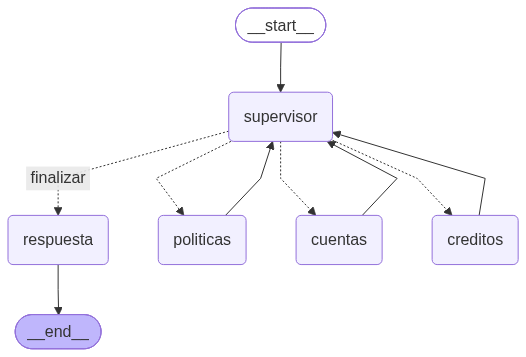

In [12]:
from IPython.display import Image
try:
    display(Image(sucursal.get_graph().draw_mermaid_png()))
except Exception:
    print(sucursal.get_graph().draw_mermaid())    # pégalo en https://mermaid.live

## Paso 12 · ▶️ Gradio: ver la colaboración en vivo
| Zona | Qué muestra |
|---|---|
| Diagrama de secuencia | Una columna por participante; cada fila es un mensaje |
| Fragmentos recuperados | Qué trozos del manual encontró el RAG, de qué **archivo y página** y con qué *score* |
| Respuesta | El texto final con citas |

| Color | Significado |
|---|---|
| 🟦 azul | Usuario ↔ Supervisor |
| 🟪 índigo | Supervisor **delega** |
| ⬛ gris | Agente **devuelve** su aporte |
| 🟧 naranja | Búsqueda **RAG** en el manual |
| 🟩 verde | Herramienta de Python |

`sucursal.stream(..., stream_mode='updates')` entrega un aviso **cada vez que termina un nodo**; con `yield` redibujamos la interfaz.

In [13]:
import gradio as gr

CARRILES = ['Usuario', 'Supervisor', 'Agente Políticas', 'Agente Cuentas', 'Agente Créditos']
ICONOS   = {'Usuario': '👤', 'Supervisor': '🧑‍💼', 'Agente Políticas': '📚', 'Agente Cuentas': '💰', 'Agente Créditos': '🧮'}
COLORES  = {'Pregunta': '#2563eb', 'Respuesta': '#2563eb', 'Delegación': '#4f46e5',
            'Resultado': '#475569', 'RAG': '#d97706', 'Herramienta': '#0d9488'}

def dibujar_secuencia(eventos):
    n = len(CARRILES)
    # Encabezado (colores fijos: se lee igual en tema claro y oscuro)
    cab = ''.join(f'<div style="text-align:center;font-weight:700;color:#0f172a;padding:8px;'
                  f'background:#e2e8f0;border-radius:8px;font-size:13px">{ICONOS[c]} {c}</div>' for c in CARRILES)
    filas = ''
    for i, ev in enumerate(eventos, start=1):
        a, b = CARRILES.index(ev['de']), CARRILES.index(ev['para'])
        color = COLORES[ev['tipo']]
        izq, der = min(a, b), max(a, b)
        etiqueta = f'{i}. {ev["accion"][:45]}'
        if a == b:    # el participante trabaja "por dentro" (RAG, herramienta, decisión de finalizar)
            flecha = (f'<div style="border:2px dashed {color};border-radius:8px;padding:2px;'
                      f'text-align:center;color:{color};font-weight:700">↻ {ev["tipo"]}</div>')
        else:
            linea = f'<div style="flex:1;height:3px;background:{color}"></div>'
            flecha = (f'<div style="display:flex;align-items:center;color:{color}">'
                      + (linea + '▶' if b > a else '◀' + linea) + '</div>')
        filas += (f'<div style="grid-column:{izq + 1}/{der + 2};padding:2px 10%">'
                  f'<div style="font-size:12px;color:{color};font-weight:600;text-align:center;'
                  f'white-space:nowrap;overflow:hidden;text-overflow:ellipsis">{etiqueta}</div>{flecha}</div>')
    return (f'<div style="background:#ffffff;border-radius:12px;padding:12px;color:#0f172a">'
            f'<div style="display:grid;grid-template-columns:repeat({n},minmax(0,1fr));gap:6px 0">{cab}{filas}</div></div>')

# def tabla_fragmentos():
#     return [[f['consulta'], f['fuente'], f['score'], f['texto']] for f in FRAGMENTOS_USADOS]
# NUEVO (reto): una columna más con la página, para comprobar la cita del agente contra el PDF
def tabla_fragmentos():
    return [[f['consulta'], f['fuente'], f['pagina'], f['score'], f['texto']] for f in FRAGMENTOS_USADOS]

def atender(pregunta):
    BITACORA.clear(); FRAGMENTOS_USADOS.clear()
    registrar('Usuario', 'Supervisor', 'Pregunta', 'pregunta', pregunta)
    yield dibujar_secuencia(BITACORA), tabla_fragmentos(), '⏳ Trabajando…'
    try:
        # Cada vez que un nodo termina, LangGraph nos avisa y redibujamos
        for paso in sucursal.stream(estado_inicial(pregunta), stream_mode='updates', config={'recursion_limit': 30}):
            nodo = list(paso)[0]
            if nodo == 'respuesta':
                yield dibujar_secuencia(BITACORA), tabla_fragmentos(), paso['respuesta']['respuesta']
            else:
                yield dibujar_secuencia(BITACORA), tabla_fragmentos(), f'⏳ Terminó: {nodo}'
    except Exception as error:
        yield dibujar_secuencia(BITACORA), tabla_fragmentos(), f'⛔ Error: {error}'

with gr.Blocks(title='Sucursal multiagente con RAG') as demo:
    gr.Markdown('# 🏦 Sucursal multiagente con RAG\nUn **Supervisor** delega en tres agentes; el de **Políticas** busca en el manual (RAG). Datos ficticios.')
    pregunta = gr.Textbox(label='Pregunta del cliente', value='¿Qué documentos necesito para pedir un crédito de moto?')
    gr.Examples([['¿Qué documentos necesito para pedir un crédito de moto?'],
                 ['¿Cuánto saldo tengo?'],
                 ['¿Qué seguros son obligatorios y en cuánto tiempo responden un reclamo?'],
                 ['Quiero una moto de 20.000.000: ¿cuál es el aporte mínimo, me alcanza con mi saldo y cuánto pagaría a 36 meses con 5.000.000 de aporte?'],
                 ['¿Puedo pagar el crédito con criptomonedas?'],
                 # NUEVO (reto): dos preguntas que la circular 2026-07 cambió (aporte de motos y horario)
                 ['¿Cuál es el aporte mínimo para una moto nueva?'],
                 ['¿A qué hora cierran la sucursal los sábados?']], inputs=pregunta)
    boton = gr.Button('Preguntar', variant='primary')
    secuencia = gr.HTML()
    respuesta_txt = gr.Textbox(label='Respuesta', lines=6)
    # fragmentos_tbl = gr.Dataframe(headers=['Consulta', 'Fuente', 'Score', 'Fragmento'], wrap=True, interactive=False,
    #                               label='📚 Fragmentos recuperados por el RAG', column_widths=['20%', '18%', '8%', '54%'])
    # NUEVO (reto): columna 'Página' (debe coincidir con la que devuelve tabla_fragmentos)
    fragmentos_tbl = gr.Dataframe(headers=['Consulta', 'Fuente', 'Página', 'Score', 'Fragmento'], wrap=True, interactive=False,
                                  label='📚 Fragmentos recuperados por el RAG', column_widths=['18%', '20%', '7%', '7%', '48%'])
    boton.click(atender, pregunta, [secuencia, fragmentos_tbl, respuesta_txt])

# ¿Estamos en Colab? (el módulo google.colab solo existe allí)
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# share=EN_COLAB → en Colab crea además un enlace público temporal (solo datos ficticios);
#                  en tu PC la interfaz solo se abre en tu equipo (http://127.0.0.1:7860)
# debug=False    → la celda termina y puedes seguir ejecutando otras celdas
demo.launch(share=EN_COLAB, debug=False)

* Running on local URL:  http://127.0.0.1:7860


* To create a public link, set `share=True` in `launch()`.


## Paso 13 · ▶️ Cerrar la interfaz
Apaga el servidor de Gradio. Si cambias código, ejecuta este paso, vuelve a ejecutar lo que cambiaste y después el paso 12.

In [14]:
# Apaga el servidor de Gradio (libera el puerto y el enlace público)
demo.close()

Closing server running on port: 7860


## 🎯 Recorrido guiado en la interfaz
| # | Pregunta | Qué observar |
|---|---|---|
| 1 | «¿Qué documentos necesito…?» | Solo delega a **Políticas**; ↻ naranja = búsqueda RAG; en la tabla, fragmentos de `02_Requisitos_y_Documentacion.pdf` con su página |
| 2 | «¿Cuánto saldo tengo?» | Solo **Cuentas**: no hace falta RAG para un dato |
| 3 | «¿Qué seguros… y reclamos?» | Políticas puede buscar **dos veces** (una por tema): el agente decide qué buscar |
| 4 | Pregunta mixta de la moto | Los **tres** agentes: documento + dato + cálculo |
| 5 | «¿Puedo pagar con criptomonedas?» | El manual no lo dice → debe responder **"El manual no tiene esa información"**, no inventar |
| 6 | «¿Cuál es el aporte mínimo para una moto nueva?» | Recupera el manual (10 %) y **adjunta** la circular (15 %): debe responder **15 %** y citar las dos |
| 7 | «¿A qué hora cierran los sábados?» | Igual que la 6: ATR-001 dice 12:00, la circular dice **13:00** |

## 🤔 Preguntas para discutir
1. ¿Por qué el saldo **no** se pone en el manual y se consulta con RAG?
2. ¿Qué pasa si `chunk_size` es muy pequeño (50) o muy grande (2000)? Pruébalo en el paso 4.
3. ¿Qué ventaja tiene que la búsqueda sea una **herramienta** del agente (RAG agéntico) y no un paso fijo antes del LLM?
4. ¿Cómo verificarías que una cita `[archivo.md]` es real y no inventada por el LLM?

## 🧪 Ejercicio
1. Agrega un séptimo PDF a `manual_pdf/` (por ejemplo, una circular nueva). Re-ejecuta desde el paso 3: la **huella** cambia y el índice se reconstruye solo.
2. En `buscar` (paso 6) comenta el bloque 2) que adjunta las circulares y repite la pregunta 6. ¿Qué aporte mínimo responde ahora el agente? ¿Empeoran las respuestas mixtas (seguros + reclamos)?
3. Agrega un cuarto agente **Agente de Reclamos** que use el mismo índice pero con instrucciones distintas, y conéctalo al Supervisor.

## ⚠️ Errores frecuentes
| Síntoma | Causa | Qué hacer |
|---|---|---|
| `GROQ_API_KEY` vacía / error 401 | No está en `.env` (local) o en Secrets, o falta dar acceso al notebook | Local: agrégala a `.env` · Colab: 🔑 Secrets → agregar `GROQ_API_KEY` y activar el acceso |
| La interfaz no se ve dentro de VS Code | El visor del notebook no muestra la vista incrustada | Abre en el navegador la URL local que imprime el paso 12 (`http://127.0.0.1:7860`) |
| La descarga del modelo de embeddings tarda | Primera vez (en Colab, en cada sesión) | Espera; luego queda en la caché de Hugging Face |
| El agente responde sin citar | El LLM ignoró la instrucción | Revisa `INSTRUCCIONES['politicas']`; haz la pregunta más concreta |
| `BadRequestError ... output_parse_failed` | El modelo generó una llamada a herramienta mal formada (3 veces seguidas) | Vuelve a ejecutar la celda; es intermitente |
| Error 429 de Groq | Muchas llamadas (cada agente usa el LLM) | Espera unos segundos |
| Cambié el manual y no se refleja | El índice se creó con los textos viejos | Re-ejecuta los pasos 3, 4 y 5: la huella detecta el cambio y reconstruye `indice_faiss/` |
| `FileNotFoundError: No hay PDFs` | Falta la carpeta `manual_pdf/` junto al notebook | Cópiala (en Colab, súbela) con los 6 PDFs |
| Quiero forzar que se reconstruya el índice | — | Borra la carpeta `indice_faiss/` y re-ejecuta el paso 5 |

## ➡️ Siguiente sesión: MCP y A2A
En esta arquitectura todo vive **en el mismo notebook**. En el notebook `06_MCP_A2A_LangGraph_Gradio.ipynb` (no incluido en esta carpeta):
- las herramientas de **Cuentas** pasan a un **servidor MCP** (cualquier agente puede usarlas),
- el **Agente de Créditos** se publica como **agente A2A** (otro equipo podría mantenerlo).

## Fuentes (consultadas el 28-10-2026)
- [LangChain: PyPDFLoader](https://docs.langchain.com/oss/python/integrations/document_loaders/pypdfloader) · [FAISS](https://docs.langchain.com/oss/python/integrations/vectorstores/faiss)
- [LangChain: RAG](https://docs.langchain.com/oss/python/langchain/rag) · [Vector stores](https://docs.langchain.com/oss/python/integrations/vectorstores)
- [LangChain: create_agent](https://docs.langchain.com/oss/python/langchain/agents) · [LangGraph: multi-agent](https://docs.langchain.com/oss/python/langchain/multi-agent)
- [sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2)